# Visualización de Datos - PEC 2

## Visualización 2 - Waffle Chart

### Descripción del conjunto de datos y objetivo

- Conjunto de datos: [Estadísticas Presupuestos Generales del Estado Consolidados 2025](https://www.sepg.pap.hacienda.gob.es/sitios/sepg/es-ES/Presupuestos/accesodocumentacion/DocumentacionEstadisticas/Estadisticas/Documents/2025-P/01%20Presupuestos%20Generales%20del%20Estado%20Consolidados.xlsx)
- Contexto sobre el conjunto de datos en la web del [Ministerio de Hacienda](https://www.sepg.pap.hacienda.gob.es/sitios/sepg/es-ES/Presupuestos/DocumentacionEstadisticas/Estadisticas/Paginas/Estadisticas.aspx)
- Objetivo: se pretende realizar una visualización de datos que nos dé una idea del reparto presupuestario para cada partida.
  

### Lectura de los datos

In [1]:
import csv
from itertools import islice

# Filas 7 a 35 (incluidas) y columnas 1 y 11 del CSV original.
with open(
    "01 Presupuestos Generales del Estado Consolidados.csv",
    encoding="cp1252",
    newline="",
) as archivo:
    lector = csv.reader(archivo, delimiter=";")
    presupuestos = {
        fila[0]: int(fila[10].replace(".", ""))
        for fila in islice(lector, 6, 34)
    }

presupuestos


{'Justicia': 2231,
 'Defensa': 12317,
 'Seguridad ciudadana e Instituciones penitenciarias': 10673,
 'Política Exterior y de cooperación para el desarrollo': 2151,
 'Pensiones': 190687,
 'Otras Prestaciones Económicas': 22299,
 'Servicios Sociales y Promoción Social': 5744,
 'Fomento del empleo': 7516,
 'Desempleo': 21278,
 'Acceso a la Vivienda y Fomento de la Edificación': 3483,
 'Gestión y administración de trabajo y economía social': 119,
 'Gestión y administración de la inclusión, de la S.S. y de la migración': 6965,
 'Sanidad': 5505,
 'Educación': 5338,
 'Cultura': 1652,
 'Agricultura, Pesca y Alimentación': 8412,
 'Industria y Energía': 9796,
 'Comercio, Turismo y PYMES': 3095,
 'Subvenciones al transporte': 3446,
 'Infraestructuras y ecosistemas resilientes': 12578,
 'Investigación civil': 15980,
 'Investigación militar': 1833,
 'Otras actuaciones de carácter económico': 1433,
 'Órganos Constitucionales, Gobierno y otros': 855,
 'Servicios de carácter general': 25939,
 'Adminis

### Limpieza y adecuación del conjunto de datos

Como son muchos grupos, nos quedamos con los 10 primeros. El resto lo dejaremos agrupado como "resto"

In [2]:
# Ordenar las partidas de mayor a menor importe.
partidas_ordenadas = sorted(
    presupuestos.items(),
    key=lambda partida: partida[1],
    reverse=True,
)

presupuestos_agrupados = dict(partidas_ordenadas[:10])
presupuestos_agrupados["resto"] = sum(
    importe for _, importe in partidas_ordenadas[10:]
)

presupuestos_agrupados

{'Pensiones': 190687,
 'Transferencias a otras Administraciones Públicas': 66274,
 'Deuda Pública': 31275,
 'Servicios de carácter general': 25939,
 'Otras Prestaciones Económicas': 22299,
 'Desempleo': 21278,
 'Investigación civil': 15980,
 'Infraestructuras y ecosistemas resilientes': 12578,
 'Defensa': 12317,
 'Seguridad ciudadana e Instituciones penitenciarias': 10673,
 'resto': 71324}

### Generación de la visualización tipo Waffle Chart


Se distribuyen 100 cuadrados mediante el método de mayores restos para conservar el total. Cada cuadrado representa aproximadamente el 1 % del gasto, en una cuadrícula de 10 × 10.

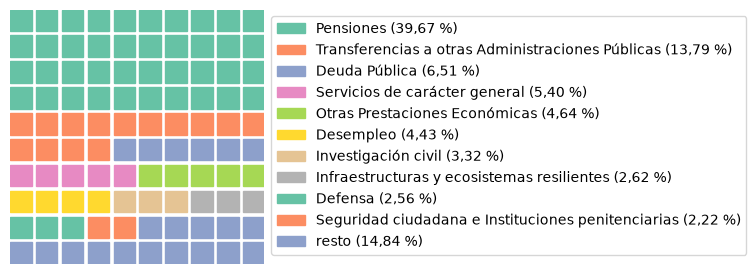

In [3]:
from pywaffle import Waffle
import matplotlib.pyplot as plt

total = sum(presupuestos_agrupados.values())
porcentajes = {
    k: v / total * 100
    for k, v in presupuestos_agrupados.items()
}

# Repartir 100 cuadrados: parte entera y sobrantes a los mayores restos.
cuadrados = {k: int(v) for k, v in porcentajes.items()}
orden_restos = sorted(
    porcentajes,
    key=lambda k: porcentajes[k] - cuadrados[k],
    reverse=True,
)
for k in orden_restos[:100 - sum(cuadrados.values())]:
    cuadrados[k] += 1

fig = plt.figure(
    FigureClass=Waffle,
    rows=10,
    columns=10,
    values={
        f"{nombre} ({porcentajes[nombre]:.2f} %)".replace(".", ","): cantidad
        for nombre, cantidad in cuadrados.items()
    },
    vertical=True,  # Rellenar por filas, de izquierda a derecha.
    starting_location="NW",  # Empezar en la esquina superior izquierda.
    legend={
        "loc": "upper left",
        "bbox_to_anchor": (1, 1)
    }
)

plt.show()